In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import matplotlib.pyplot as plt
import missingno as msno

# Data Cleaning (Made by Ann)

In [5]:
df = pd.read_csv('/content/US_Accidents_March23_sampled_500k.zip', encoding ='latin1')

In [6]:
df = df.drop(columns = ['End_Lat', 'End_Lng', 'ID', 'Start_Lat', 'Start_Lng', 'Description', 'Street',
                        'Airport_Code', 'Bump', 'Crossing', 'Give_Way',
                        'Junction', 'No_Exit', 'Railway', 'Roundabout',
                        'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal',
                        'Turning_Loop', 'Amenity', 'Source', 'Weather_Timestamp'])

In [7]:
df = df.drop(columns= ['Timezone', 'Country'])

In [8]:
df = df.drop( columns= ['Civil_Twilight', 'Astronomical_Twilight',
                        'Nautical_Twilight'])
df.dropna(subset =['Sunrise_Sunset'], inplace = True)

In [9]:
df = df.drop( columns= ['Wind_Chill(F)'])

In [10]:
df['Start_Time'] = pd.to_datetime(
    df['Start_Time'],
    errors = 'coerce',
    format = 'mixed'
)

df['End_Time'] = pd.to_datetime(
    df['End_Time'],
    errors = 'coerce',
    format = 'mixed'
)

In [11]:
df['Zipcode'] = df['Zipcode'].astype(str).str[:5] #stip to get 5 zip standard

df['Zipcode'].value_counts(dropna = False)

,count
Zipcode,
27610,846
32819,788
33186,745
91761,739
70808,716
...,...
05001,1
44450,1
03261,1


In [12]:
df['Weather_Condition'] = df['Weather_Condition'].replace('N/A Precipitation','')
df['Weather_Condition'] = df['Weather_Condition'].str.lower()

df['Clear_Weather'] = df['Weather_Condition'].str.contains('fair|clear')
df['Rain'] = df['Weather_Condition'].str.contains('rain|drizzle|shower')
df['Ice'] = df['Weather_Condition'].str.contains('freezing|hail|wintry|sleet|ice|pellet')
df['Windy'] = df['Weather_Condition'].str.contains('funnel|tornado|windy|whirlwind|squall')
df['Thunder'] = df['Weather_Condition'].str.contains('thunder|storm')
df['Cloudy'] = df['Weather_Condition'].str.contains('overcast|funnel|cloudy')
df['Smoke/Dust'] = df['Weather_Condition'].str.contains('smoke|sand|dust|haze|fog|ash|mist')
df['Snow'] = df['Weather_Condition'].str.contains('wintry|snow')
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 498517 entries, 0 to 499999
Data columns (total 25 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   Severity           498517 non-null  int64         
 1   Start_Time         498517 non-null  datetime64[ns]
 2   End_Time           498517 non-null  datetime64[ns]
 3   Distance(mi)       498517 non-null  float64       
 4   City               498517 non-null  object        
 5   County             498517 non-null  object        
 6   State              498517 non-null  object        
 7   Zipcode            498517 non-null  object        
 8   Temperature(F)     488221 non-null  float64       
 9   Humidity(%)        487561 non-null  float64       
 10  Pressure(in)       489757 non-null  float64       
 11  Visibility(mi)     487398 non-null  float64       
 12  Wind_Direction     487496 non-null  object        
 13  Wind_Speed(mph)    461707 non-null  float64      

In [13]:
df = df.dropna(subset=['Temperature(F)','Humidity(%)','Pressure(in)',
                 'Visibility(mi)', 'Wind_Direction', 'Wind_Speed(mph)',
                 'Precipitation(in)', 'Weather_Condition'], how= 'all')

#drop NaN weather condition because we need the weather data
df.dropna(subset =['Weather_Condition'], inplace = True)

In [14]:
df['Wind_Direction'] = df['Wind_Direction'].replace({
    "North" : "N",
    "East" : "E",
    "South" : "S",
    "Calm" : "CALM",
    "West" : "W",
    "Variable" : "VAR"
})

In [15]:
df['Wind_Direction'] = df['Wind_Direction'].fillna("Unknown")

In [16]:
df[df['Temperature(F)'] > 120]['Temperature(F)']

,Temperature(F)
63069,140.0
193548,207.0
426439,196.0


In [17]:
df = df[df['Temperature(F)'] <=120] #drop the temperature outside 130°F
df['Temperature(F)'] = df['Temperature(F)'].fillna(df['Temperature(F)'].median())
df['Temperature(F)'].describe()

,Temperature(F)
count,485850.000000
mean,61.659988
std,18.984996
min,-35.000000
25%,49.000000
50%,64.000000
75%,76.000000
max,117.000000


In [18]:
s = df.isna().mean()*100
s[s>0]

,0
Humidity(%),0.134198
Pressure(in),0.090769
Visibility(mi),0.254605
Wind_Speed(mph),5.553154
Precipitation(in),27.336215


In [19]:
df['Humidity(%)'] = df['Humidity(%)'].fillna(df['Humidity(%)'].median())

In [20]:
df.loc[((df['Pressure(in)'] < 26.35) | (df['Pressure(in)'] > 32)), 'Pressure(in)'] = np.nan

In [21]:
df.loc[(df['Wind_Speed(mph)']>321), 'Wind_Speed(mph)'] = np.nan

In [22]:
df.loc[df['Visibility(mi)']>=100,'Visibility(mi)'] = 10
df['Visibility(mi)'] = df['Visibility(mi)'].fillna(10)

In [23]:
s = df.isna().mean()*100
s[s>0]

,0
Pressure(in),3.068643
Wind_Speed(mph),5.553360
Precipitation(in),27.336215


In [24]:
df['Time_Hour'] = df['Start_Time'].dt.hour
df['Time_Minute'] = df['Start_Time'].dt.minute
df['Year'] = df['Start_Time'].dt.year
df['Month'] = df['Start_Time'].dt.month
df['Date'] = df['Start_Time'].dt.day

In [25]:
df[['Time_Hour','Time_Minute','Year','Month','Date']].head(5)

,Time_Hour,Time_Minute,Year,Month,Date
0,10,10,2019,6,12
1,23,37,2022,12,3
2,13,13,2022,8,20
3,17,43,2022,2,21
4,1,46,2020,12,4


In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 485850 entries, 0 to 499999
Data columns (total 30 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   Severity           485850 non-null  int64         
 1   Start_Time         485850 non-null  datetime64[ns]
 2   End_Time           485850 non-null  datetime64[ns]
 3   Distance(mi)       485850 non-null  float64       
 4   City               485850 non-null  object        
 5   County             485850 non-null  object        
 6   State              485850 non-null  object        
 7   Zipcode            485850 non-null  object        
 8   Temperature(F)     485850 non-null  float64       
 9   Humidity(%)        485850 non-null  float64       
 10  Pressure(in)       470941 non-null  float64       
 11  Visibility(mi)     485850 non-null  float64       
 12  Wind_Direction     485850 non-null  object        
 13  Wind_Speed(mph)    458869 non-null  float64      

# Data Modeling (Max)

My goal for this section is to create a multi-class classification data model to find out the severity of a car accident based on the data remaining in this dataset post-cleaning.

In [149]:
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, KFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils import compute_sample_weight
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import xgboost as xgb

Encoding

In [81]:
df['Snow'] = df['Snow'].astype(int)
df['Rain'] = df['Rain'].astype(int)
df['Ice'] = df['Ice'].astype(int)
df['Windy'] = df['Windy'].astype(int)
df['Thunder'] = df['Thunder'].astype(int)
df['Cloudy'] = df['Cloudy'].astype(int)
df['Smoke/Dust'] = df['Smoke/Dust'].astype(int)
df['Clear_Weather'] = df['Clear_Weather'].astype(int)
df['Sunrise_Sunset'] = df['Clear_Weather'].astype("category").cat.codes
df['Wind_Direction'] = df['Wind_Direction'].astype("category").cat.codes
df['State'] = df['State'].astype('category').cat.codes
df['City'] = df['City'].astype('category').cat.codes

In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 485850 entries, 0 to 499999
Data columns (total 30 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   Severity           485850 non-null  int64         
 1   Start_Time         485850 non-null  datetime64[ns]
 2   End_Time           485850 non-null  datetime64[ns]
 3   Distance(mi)       485850 non-null  float64       
 4   City               485850 non-null  object        
 5   County             485850 non-null  object        
 6   State              485850 non-null  object        
 7   Zipcode            485850 non-null  object        
 8   Temperature(F)     485850 non-null  float64       
 9   Humidity(%)        485850 non-null  float64       
 10  Pressure(in)       470941 non-null  float64       
 11  Visibility(mi)     485850 non-null  float64       
 12  Wind_Direction     485850 non-null  int8          
 13  Wind_Speed(mph)    458869 non-null  float64      

In [129]:
X = df[['City','State','Zipcode','Temperature(F)','Humidity(%)','Pressure(in)', 'Visibility(mi)','Wind_Speed(mph)','Precipitation(in)',
        'Sunrise_Sunset','Rain','Ice','Windy','Thunder','Cloudy','Smoke/Dust',
        'Snow','Time_Hour','Month','Date','Wind_Direction','Time_Minute']]

In [130]:
y = df['Severity']

In [131]:
len(X),len(y)

(485850, 485850)

In [132]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=50)

In [133]:
len(X_train), len(y_train), len(X_test), len(y_test)

(340095, 340095, 145755, 145755)

In [134]:
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train)
y_test = label_encoder.transform(y_test)

In [135]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [136]:
weight = compute_sample_weight('balanced', y_train)

In [146]:
model_unchanged = xgb.XGBClassifier(random_state=50)

model_unchanged.fit(X_train, y_train,)

y_pred = model_unchanged.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy : {accuracy: 4f}")
print(f"\nClassification Report : \n", classification_report(y_test, y_pred))
print(f"\nConfusion Matrix : \n", confusion_matrix(y_test, y_pred))

Accuracy :  0.809914

Classification Report : 
               precision    recall  f1-score   support

           0       0.28      0.01      0.02      1277
           1       0.82      0.98      0.89    116122
           2       0.60      0.19      0.29     24625
           3       0.47      0.02      0.03      3731

    accuracy                           0.81    145755
   macro avg       0.54      0.30      0.31    145755
weighted avg       0.77      0.81      0.76    145755


Confusion Matrix : 
 [[    10   1260      7      0]
 [    24 113276   2780     42]
 [     2  19894   4699     30]
 [     0   3360    307     64]]


In [151]:
param_grid = {
    'n_estimators' : [100,200,300,500],
    'learning_rate' : [0.01, 0.1, 0.2],
    'max_depth' : [3,6,9],
    'min_child_weight' : [1,3,5],
    'subsample' : [0.7, 0.85, 1.0],
    'colsample_bytree' : [0.7, 0.85, 1.0],
    'reg_alpha' : [0,0.01,0.1,1,10,100],
    'reg_lambda' : [0.5,0.7,1,1.3]
}

In [147]:
model = xgb.XGBClassifier(random_state=50)

In [165]:
grid_search = RandomizedSearchCV(model, param_grid, cv = 2, scoring='accuracy', n_iter = 24, n_jobs =-1, verbose=2)
grid_search.fit(X_train, y_train, sample_weight = weight)

best_model = grid_search.best_estimator_

print("Best Parameters:", grid_search.best_params_)
print("Best Accuracy:", grid_search.best_score_)

Fitting 2 folds for each of 24 candidates, totalling 48 fits
Best Parameters: {'subsample': 1.0, 'reg_lambda': 0.5, 'reg_alpha': 0.1, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 9, 'learning_rate': 0.2, 'colsample_bytree': 0.85}
Best Accuracy: 0.7088695838239261


In [166]:
y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy : {accuracy: 4f}")
print(f"\nClassification Report : \n", classification_report(y_test, y_pred))
print(f"\nConfusion Matrix : \n", confusion_matrix(y_test, y_pred))

Accuracy :  0.674118

Classification Report : 
               precision    recall  f1-score   support

           0       0.11      0.55      0.18      1277
           1       0.90      0.70      0.79    116122
           2       0.38      0.61      0.47     24625
           3       0.13      0.33      0.19      3731

    accuracy                           0.67    145755
   macro avg       0.38      0.55      0.41    145755
weighted avg       0.78      0.67      0.71    145755


Confusion Matrix : 
 [[  698   406   137    36]
 [ 4843 81301 23669  6309]
 [  755  7368 15040  1462]
 [   89  1437   988  1217]]


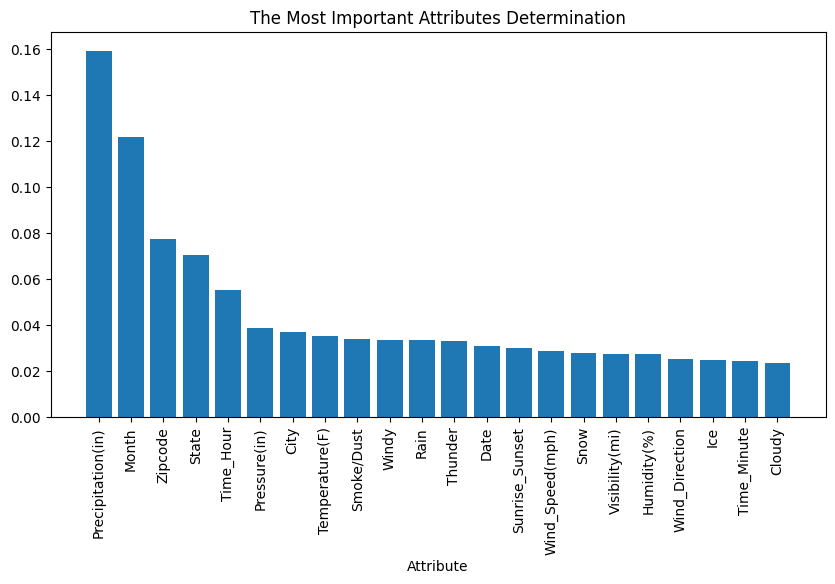

In [169]:
feature_importance = best_model.feature_importances_
feature_names = X.columns

sorted = np.argsort(feature_importance)[::-1]
plt.figure(figsize=(10,5))
plt.bar(range(len(feature_importance)), feature_importance[sorted], align='center')
plt.xticks(range(len(feature_importance)), np.array(feature_names)[sorted], rotation=90)
plt.xlabel("Attribute")
plt.title("The Most Important Attributes Determination")
plt.show()